In [52]:
import os
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder

In [4]:
TRAIN_IMAGES_DIR = "/content/drive/MyDrive/dental_xray_dataset/train/images"
TRAIN_LABELS_CSV = "/content/drive/MyDrive/dental_xray_dataset/train/labels/_annotations.csv"

In [5]:
df = pd.read_csv(TRAIN_LABELS_CSV)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

Dataset shape: (8030, 8)

Columns:
['filename', 'width', 'height', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

First 5 rows:
                                           filename  width  height     class  \
0  0674_jpg.rf.e02a155a0c135687b9301ff9a20d220a.jpg    512     256   Implant   
1  0674_jpg.rf.e02a155a0c135687b9301ff9a20d220a.jpg    512     256  Fillings   
2  0674_jpg.rf.e02a155a0c135687b9301ff9a20d220a.jpg    512     256   Implant   
3  0674_jpg.rf.e02a155a0c135687b9301ff9a20d220a.jpg    512     256   Implant   
4  0674_jpg.rf.e02a155a0c135687b9301ff9a20d220a.jpg    512     256   Implant   

   xmin  ymin  xmax  ymax  
0   175   116   206   153  
1   170   109   189   133  
2   221   124   257   178  
3   302   126   329   175  
4   335   114   360   154  


In [6]:
class_counts = df["class"].value_counts()
print("\nClass counts:")
print(class_counts)


Class counts:
class
Fillings          5242
Implant           1784
Cavity             576
Impacted Tooth     428
Name: count, dtype: int64


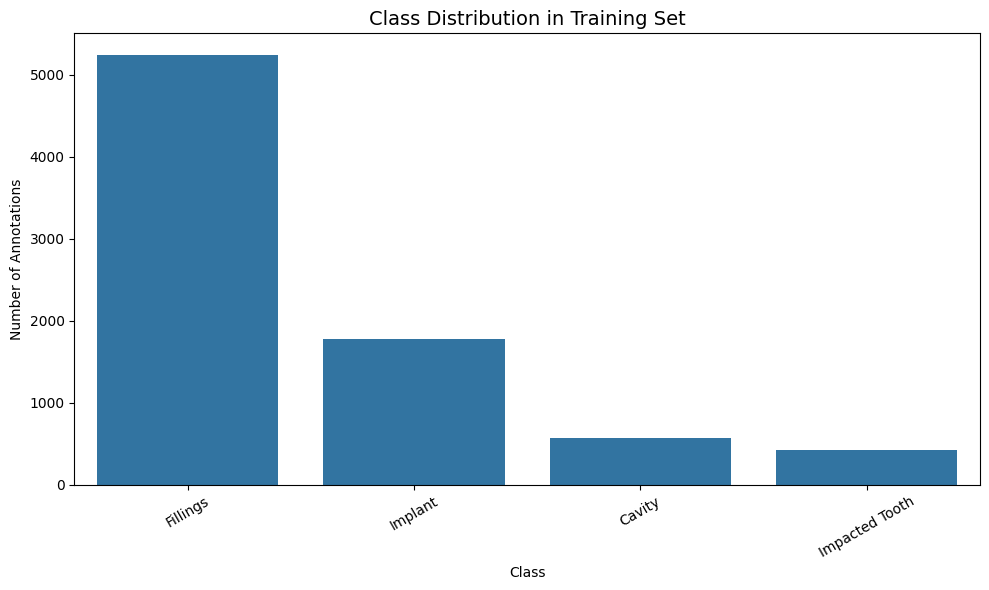

In [7]:
plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Class Distribution in Training Set", fontsize=14)
plt.xlabel("Class")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [8]:
unique_images = df["filename"].nunique()
print("\nUnique images in training annotations:", unique_images)


Unique images in training annotations: 1075


In [9]:
def show_annotated_image(image_name, df, image_dir):
    image_path = os.path.join(image_dir, image_name)
    image = cv2.imread(image_path)

    if image is None:
        print(f"Could not load image: {image_path}")
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    rows = df[df["filename"] == image_name]

    for _, row in rows.iterrows():
        xmin, ymin, xmax, ymax = int(row["xmin"]), int(row["ymin"]), int(row["xmax"]), int(row["ymax"])
        label = row["class"]

        cv2.rectangle(image, (xmin, ymin), (xmax, ymax), (255, 0, 0), 2)
        cv2.putText(image, label, (xmin, max(ymin - 10, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.title(f"Annotated Image: {image_name}")
    plt.axis("off")
    plt.show()


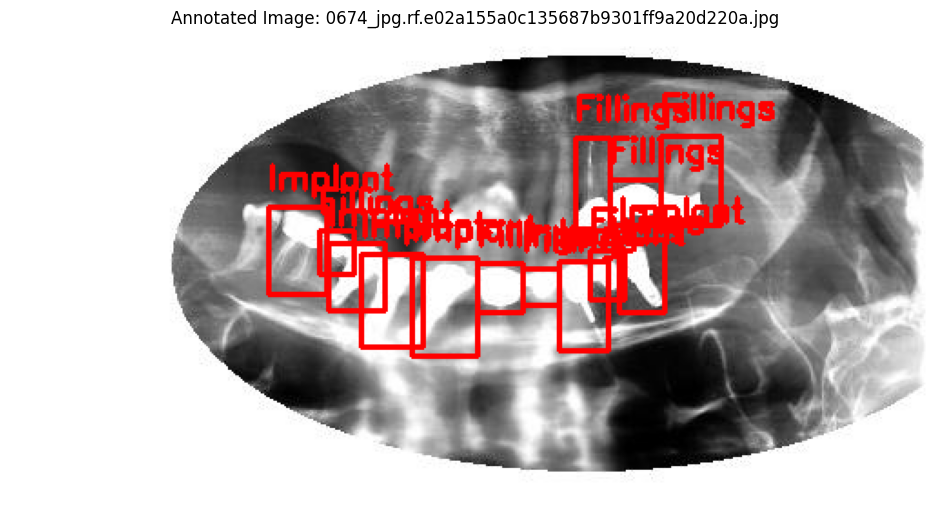

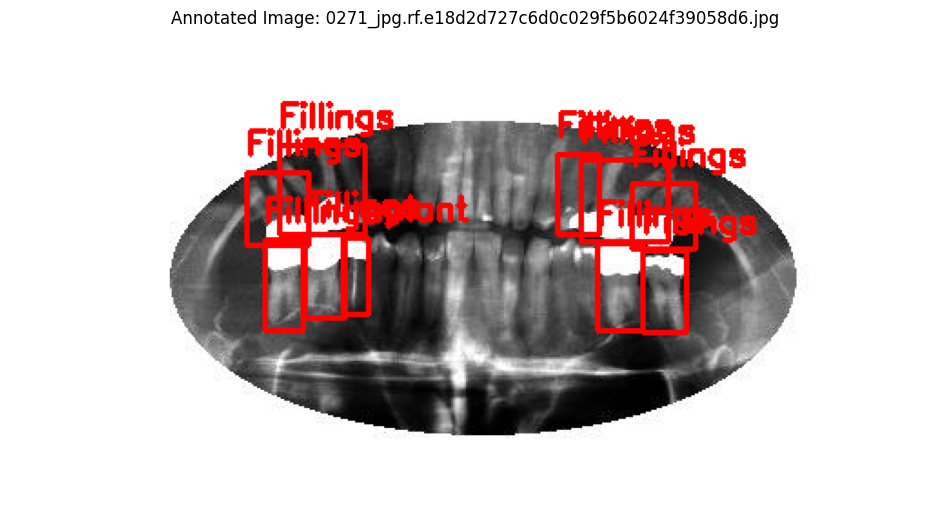

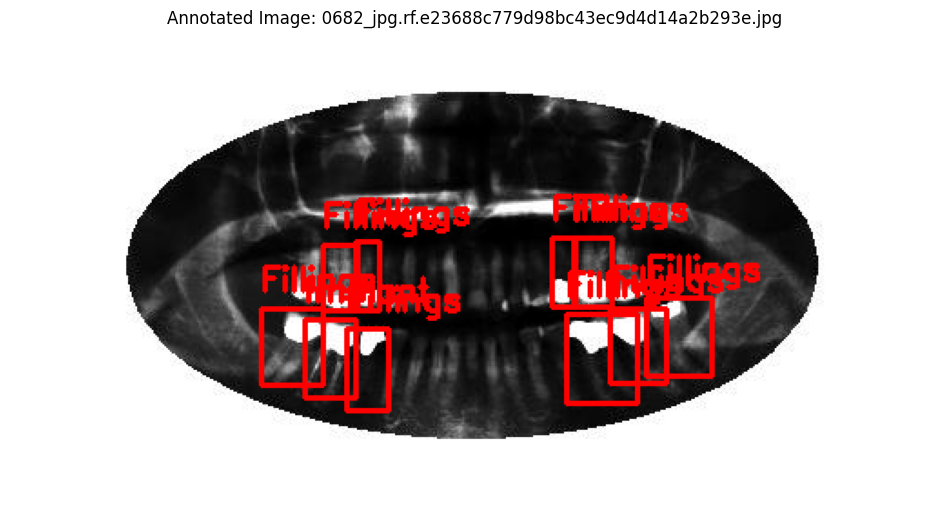

In [10]:
sample_images = df["filename"].unique()[:3]

for img_name in sample_images:
    show_annotated_image(img_name, df, TRAIN_IMAGES_DIR)

In [11]:
VALID_IMAGES_DIR = "/content/drive/MyDrive/dental_xray_dataset/valid/images"
VALID_LABELS_CSV = "/content/drive/MyDrive/dental_xray_dataset/valid/labels/_annotations.csv"

TEST_IMAGES_DIR = "/content/drive/MyDrive/dental_xray_dataset/test/images"
TEST_LABELS_CSV = "/content/drive/MyDrive/dental_xray_dataset/test/labels/_annotations.csv"

In [12]:
OUTPUT_BASE = "/content/drive/MyDrive/dental_xray_dataset_yolo"

TRAIN_OUT_IMG = os.path.join(OUTPUT_BASE, "train", "images")
TRAIN_OUT_LBL = os.path.join(OUTPUT_BASE, "train", "labels")

VALID_OUT_IMG = os.path.join(OUTPUT_BASE, "valid", "images")
VALID_OUT_LBL = os.path.join(OUTPUT_BASE, "valid", "labels")

TEST_OUT_IMG = os.path.join(OUTPUT_BASE, "test", "images")
TEST_OUT_LBL = os.path.join(OUTPUT_BASE, "test", "labels")

for path in [TRAIN_OUT_IMG, TRAIN_OUT_LBL, VALID_OUT_IMG, VALID_OUT_LBL, TEST_OUT_IMG, TEST_OUT_LBL]:
    os.makedirs(path, exist_ok=True)

print("Output folders created successfully.")

Output folders created successfully.


In [13]:
train_df = pd.read_csv(TRAIN_LABELS_CSV)
valid_df = pd.read_csv(VALID_LABELS_CSV)
test_df = pd.read_csv(TEST_LABELS_CSV)

print("Train shape:", train_df.shape)
print("Valid shape:", valid_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:", train_df.columns.tolist())

Train shape: (8030, 8)
Valid shape: (780, 8)
Test shape: (473, 8)

Train columns: ['filename', 'width', 'height', 'class', 'xmin', 'ymin', 'xmax', 'ymax']


In [14]:
def clean_annotations(df):
    df = df.dropna().copy()

    df = df[
        (df["xmin"] < df["xmax"]) &
        (df["ymin"] < df["ymax"]) &
        (df["xmin"] >= 0) &
        (df["ymin"] >= 0)
    ].copy()

    return df

train_df = clean_annotations(train_df)
valid_df = clean_annotations(valid_df)
test_df = clean_annotations(test_df)

print("After cleaning:")
print("Train:", train_df.shape)
print("Valid:", valid_df.shape)
print("Test:", test_df.shape)

After cleaning:
Train: (8027, 8)
Valid: (780, 8)
Test: (473, 8)


In [15]:
all_classes = pd.concat([
    train_df["class"],
    valid_df["class"],
    test_df["class"]
]).unique()

label_encoder = LabelEncoder()
label_encoder.fit(all_classes)

print("Classes found:")
for idx, class_name in enumerate(label_encoder.classes_):
    print(f"{idx}: {class_name}")

Classes found:
0: Cavity
1: Fillings
2: Impacted Tooth
3: Implant


In [16]:
class_names_path = os.path.join(OUTPUT_BASE, "classes.txt")

with open(class_names_path, "w") as f:
    for class_name in label_encoder.classes_:
        f.write(class_name + "\n")

print(f"Class names saved at: {class_names_path}")

Class names saved at: /content/drive/MyDrive/dental_xray_dataset_yolo/classes.txt


In [17]:
def preprocess_image(image_path, target_size=(640, 640)):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        return None

    # Denoising
    img = cv2.GaussianBlur(img, (3, 3), 0)

    # CLAHE contrast enhancement
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img = clahe.apply(img)

    # Resize
    img = cv2.resize(img, target_size)

    # Convert grayscale to 3 channels
    img_3ch = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

    return img_3ch

In [18]:
def convert_to_yolo_format(xmin, ymin, xmax, ymax, img_width, img_height):
    x_center = ((xmin + xmax) / 2) / img_width
    y_center = ((ymin + ymax) / 2) / img_height
    width = (xmax - xmin) / img_width
    height = (ymax - ymin) / img_height

    return x_center, y_center, width, height

In [19]:
def process_split(df, input_img_dir, output_img_dir, output_lbl_dir, label_encoder, target_size=(640, 640)):
    grouped = df.groupby("filename")

    for filename, group in tqdm(grouped, desc=f"Processing {os.path.basename(os.path.dirname(input_img_dir))}"):
        input_path = os.path.join(input_img_dir, filename)

        original = cv2.imread(input_path)
        if original is None:
            print(f"Skipping missing image: {input_path}")
            continue

        orig_h, orig_w = original.shape[:2]

        processed_img = preprocess_image(input_path, target_size=target_size)
        if processed_img is None:
            continue

        # Save processed image
        output_img_path = os.path.join(output_img_dir, filename)
        cv2.imwrite(output_img_path, processed_img)

        # Create matching label txt file
        txt_filename = os.path.splitext(filename)[0] + ".txt"
        output_txt_path = os.path.join(output_lbl_dir, txt_filename)

        new_w, new_h = target_size[0], target_size[1]

        with open(output_txt_path, "w") as f:
            for _, row in group.iterrows():
                class_id = label_encoder.transform([row["class"]])[0]

                # Scale bbox from original size to resized size
                xmin = row["xmin"] * (new_w / orig_w)
                xmax = row["xmax"] * (new_w / orig_w)
                ymin = row["ymin"] * (new_h / orig_h)
                ymax = row["ymax"] * (new_h / orig_h)

                x_center, y_center, width, height = convert_to_yolo_format(
                    xmin, ymin, xmax, ymax, new_w, new_h
                )

                # Safety clamp
                x_center = min(max(x_center, 0), 1)
                y_center = min(max(y_center, 0), 1)
                width = min(max(width, 0), 1)
                height = min(max(height, 0), 1)

                f.write(f"{class_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}\n")

In [20]:
process_split(train_df, TRAIN_IMAGES_DIR, TRAIN_OUT_IMG, TRAIN_OUT_LBL, label_encoder)
process_split(valid_df, VALID_IMAGES_DIR, VALID_OUT_IMG, VALID_OUT_LBL, label_encoder)
process_split(test_df, TEST_IMAGES_DIR, TEST_OUT_IMG, TEST_OUT_LBL, label_encoder)

print("All splits processed successfully.")

Processing test: 100%|██████████| 73/73 [00:31<00:00,  2.33it/s]

All splits processed successfully.


In [21]:
!pip install -q ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 30.8 MB/s eta 0:00:00


In [22]:
from ultralytics import YOLO

YOLO_DATA_YAML = "/content/drive/MyDrive/dental_xray_dataset_yolo/data.yaml"
PROJECT_DIR = "/content/drive/MyDrive/dental_xray_yolo_runs"
RUN_NAME = "baseline_yolov8n"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("YAML Path:", YOLO_DATA_YAML)
print("Project Dir:", PROJECT_DIR)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YAML Path: /content/drive/MyDrive/dental_xray_dataset_yolo/data.yaml
Project Dir: /content/drive/MyDrive/dental_xray_yolo_runs


In [23]:
if os.path.exists(YOLO_DATA_YAML):
    print("data.yaml found successfully.\n")
    with open(YOLO_DATA_YAML, "r") as f:
        print(f.read())
else:
    print("ERROR: data.yaml not found.")

ERROR: data.yaml not found.


In [24]:

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully.")

YOLO model loaded successfully.


In [27]:
import os

OUTPUT_BASE = "/content/drive/MyDrive/dental_xray_dataset_yolo"

TRAIN_OUT_IMG = os.path.join(OUTPUT_BASE, "train", "images")
VALID_OUT_IMG = os.path.join(OUTPUT_BASE, "valid", "images")
TEST_OUT_IMG = os.path.join(OUTPUT_BASE, "test", "images")

# IMPORTANT: use clean class names (no spaces)
class_names = ["Cavity", "Fillings", "Impacted_Tooth", "Implant"]

yaml_content = f"""train: {TRAIN_OUT_IMG}
val: {VALID_OUT_IMG}
test: {TEST_OUT_IMG}

nc: {len(class_names)}
names: {class_names}
"""

yaml_path = os.path.join(OUTPUT_BASE, "data.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("data.yaml created successfully at:", yaml_path)
print("\nContent:\n")
print(yaml_content)

data.yaml created successfully at: /content/drive/MyDrive/dental_xray_dataset_yolo/data.yaml

Content:

train: /content/drive/MyDrive/dental_xray_dataset_yolo/train/images
val: /content/drive/MyDrive/dental_xray_dataset_yolo/valid/images
test: /content/drive/MyDrive/dental_xray_dataset_yolo/test/images

nc: 4
names: ['Cavity', 'Fillings', 'Impacted_Tooth', 'Implant']



In [28]:
print(os.listdir("/content/drive/MyDrive/dental_xray_dataset_yolo"))

['train', 'valid', 'test', 'classes.txt', 'data.yaml']


In [29]:
from ultralytics import YOLO

YOLO_DATA_YAML = "/content/drive/MyDrive/dental_xray_dataset_yolo/data.yaml"
PROJECT_DIR = "/content/drive/MyDrive/dental_xray_yolo_runs"
RUN_NAME = "baseline_yolov8n"

model = YOLO("yolov8n.pt")

results = model.train(
    data=YOLO_DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=8,
    project=PROJECT_DIR,
    name=RUN_NAME,
    pretrained=True,
    optimizer="Adam",
    lr0=0.001,
    patience=15,
    workers=2,
    plots=True
)

Ultralytics 8.4.32 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/dental_xray_dataset_yolo/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolov8n2, nbs=64, nms=False, opset=None, optimize=False, optimizer=Adam, over

In [32]:
import os

PROJECT_DIR = "/content/drive/MyDrive/dental_xray_yolo_runs"

print("Project exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("\nRun folders:")
    print(os.listdir(PROJECT_DIR))

    for run_name in os.listdir(PROJECT_DIR):
        run_path = os.path.join(PROJECT_DIR, run_name)
        if os.path.isdir(run_path):
            print(f"\nContents of {run_name}:")
            print(os.listdir(run_path))

            weights_path = os.path.join(run_path, "weights")
            if os.path.exists(weights_path):
                print(f"Weights inside {run_name}/weights:")
                print(os.listdir(weights_path))

Project exists: True

Run folders:
['baseline_yolov8n', 'baseline_yolov8n2']

Contents of baseline_yolov8n:
['weights', 'args.yaml']
Weights inside baseline_yolov8n/weights:
[]

Contents of baseline_yolov8n2:
['weights', 'args.yaml', 'labels.jpg', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'results.csv', 'train_batch5400.jpg', 'train_batch5401.jpg', 'train_batch5402.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'BoxPR_curve.png', 'BoxF1_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix_normalized.png', 'confusion_matrix.png', 'results.png']
Weights inside baseline_yolov8n2/weights:
['last.pt', 'best.pt']


In [33]:
import os
from ultralytics import YOLO

PROJECT_DIR = "/content/drive/MyDrive/dental_xray_yolo_runs"

best_model_path = None

for run_name in sorted(os.listdir(PROJECT_DIR), reverse=True):
    run_path = os.path.join(PROJECT_DIR, run_name)
    candidate = os.path.join(run_path, "weights", "best.pt")
    if os.path.exists(candidate):
        best_model_path = candidate
        break

print("Detected best model path:", best_model_path)

if best_model_path is None:
    print("No best.pt found. Training likely failed or never completed.")
else:
    best_model = YOLO(best_model_path)
    print("Best model loaded successfully.")

Detected best model path: /content/drive/MyDrive/dental_xray_yolo_runs/baseline_yolov8n2/weights/best.pt
Best model loaded successfully.


In [35]:
train_save_dir = model.trainer.save_dir
best_model_path = os.path.join(train_save_dir, "weights", "best.pt")
print("Best model path:", best_model_path)

Best model path: /content/drive/MyDrive/dental_xray_yolo_runs/baseline_yolov8n2/weights/best.pt


In [37]:
import os
from ultralytics import YOLO

PROJECT_DIR = "/content/drive/MyDrive/dental_xray_yolo_runs"
YOLO_DATA_YAML = "/content/drive/MyDrive/dental_xray_dataset_yolo/data.yaml"

best_model_path = None

for run_name in sorted(os.listdir(PROJECT_DIR), reverse=True):
    candidate = os.path.join(PROJECT_DIR, run_name, "weights", "best.pt")
    if os.path.exists(candidate):
        best_model_path = candidate
        break

print("Using model:", best_model_path)

best_model = YOLO(best_model_path)

val_metrics = best_model.val(data=YOLO_DATA_YAML, split="val")
test_metrics = best_model.val(data=YOLO_DATA_YAML, split="test")

print("Validation and testing finished.")

Using model: /content/drive/MyDrive/dental_xray_yolo_runs/baseline_yolov8n2/weights/best.pt
Ultralytics 8.4.32 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 25.0±9.6 MB/s, size: 55.5 KB)
val: Scanning /content/drive/MyDrive/dental_xray_dataset_yolo/valid/labels.cache... 121 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 121/121 42.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.3it/s 3.4s
                   all        121        780      0.665       0.74      0.757      0.502
                Cavity         23         43      0.464      0.422      0.406      0.224
              Fillings         97        540      0.737      0.847      0.875      0.578
        Impacted_Tooth         25         38      0.584      0.777      0.788      0.562
               Implan

In [38]:
TEST_IMAGES_DIR = "/content/drive/MyDrive/dental_xray_dataset_yolo/test/images"
sample_test_images = sorted([
    os.path.join(TEST_IMAGES_DIR, f)
    for f in os.listdir(TEST_IMAGES_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])[:5]

pred_results = best_model.predict(
    source=sample_test_images,
    conf=0.25,
    save=True,
    project=PROJECT_DIR,
    name="baseline_predictions"
)

print("Predictions saved successfully.")


0: 640x640 3 Fillingss, 10.8ms
1: 640x640 1 Implant, 10.8ms
2: 640x640 2 Cavitys, 1 Fillings, 1 Impacted_Tooth, 10.8ms
3: 640x640 1 Fillings, 1 Implant, 10.8ms
4: 640x640 3 Implants, 10.8ms
Speed: 3.8ms preprocess, 10.8ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/dental_xray_yolo_runs/baseline_predictions
Predictions saved successfully.


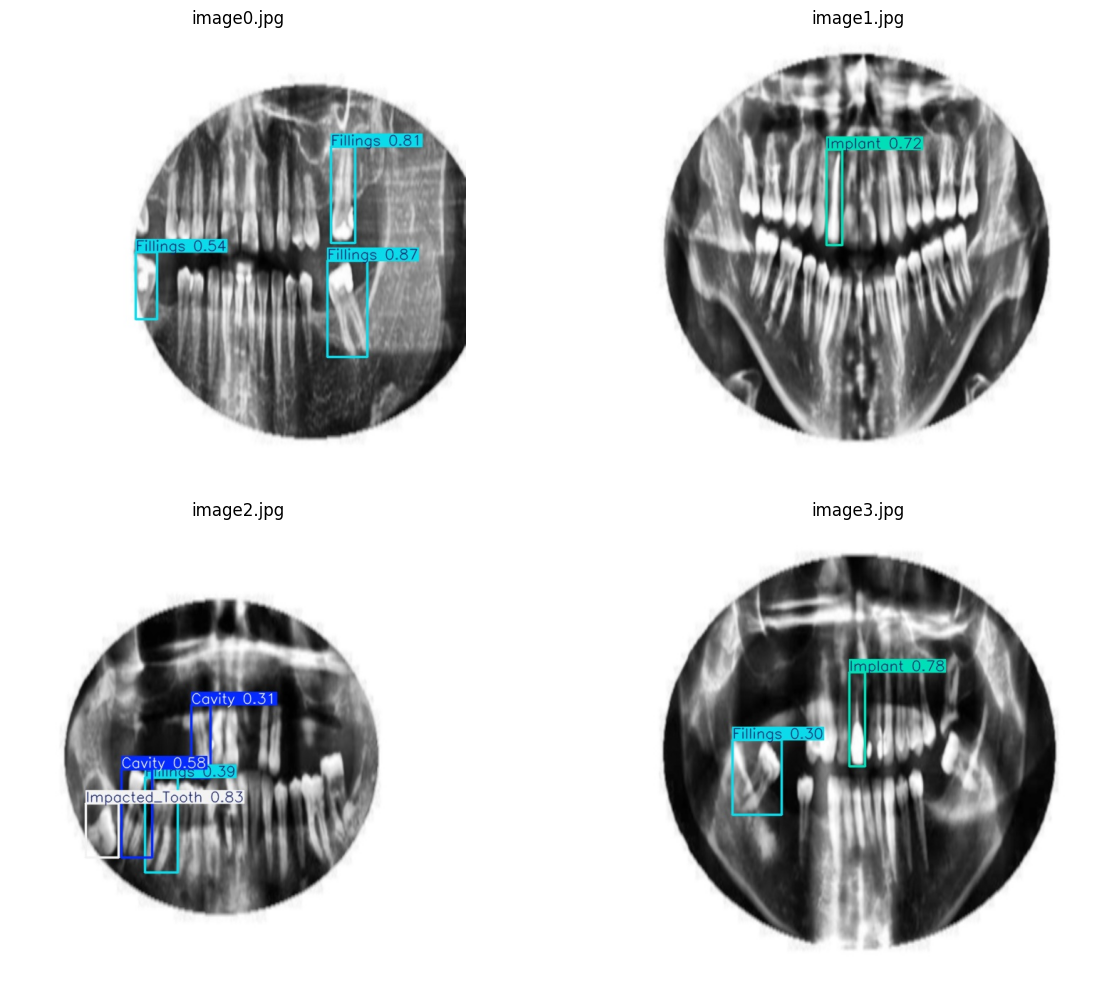

In [39]:
import cv2
import math

PRED_DIR = f"{PROJECT_DIR}/baseline_predictions"

predicted_files = sorted([
    os.path.join(PRED_DIR, f)
    for f in os.listdir(PRED_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

num_images = min(4, len(predicted_files))
cols = 2
rows = math.ceil(num_images / cols)

plt.figure(figsize=(14, 10))

for i in range(num_images):
    img = cv2.imread(predicted_files[i])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(predicted_files[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [42]:
import os
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/dental_xray_yolo_runs"

results_csv_path = None

for run_name in sorted(os.listdir(PROJECT_DIR), reverse=True):
    candidate = os.path.join(PROJECT_DIR, run_name, "results.csv")
    best_candidate = os.path.join(PROJECT_DIR, run_name, "weights", "best.pt")

    if os.path.exists(candidate) and os.path.exists(best_candidate):
        results_csv_path = candidate
        print("Using run:", run_name)
        break

print("Results CSV path:", results_csv_path)

results_df = pd.read_csv(results_csv_path)
print(results_df.head())
print("\nColumns:")
print(results_df.columns.tolist())

Using run: baseline_yolov8n2
Results CSV path: /content/drive/MyDrive/dental_xray_yolo_runs/baseline_yolov8n2/results.csv
   epoch      time  train/box_loss  train/cls_loss  train/dfl_loss  \
0      1   30.3612         1.67540         2.65066         1.37404   
1      2   55.8702         1.43130         1.90037         1.25246   
2      3   83.4897         1.39349         1.70692         1.25104   
3      4  111.2650         1.37949         1.56539         1.26008   
4      5  138.6370         1.34726         1.44686         1.22810   

   metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
0               0.64508            0.09383           0.09532   
1               0.48708            0.36804           0.27074   
2               0.58676            0.40094           0.38434   
3               0.66023            0.52074           0.56473   
4               0.64239            0.51240           0.59087   

   metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss    lr/p

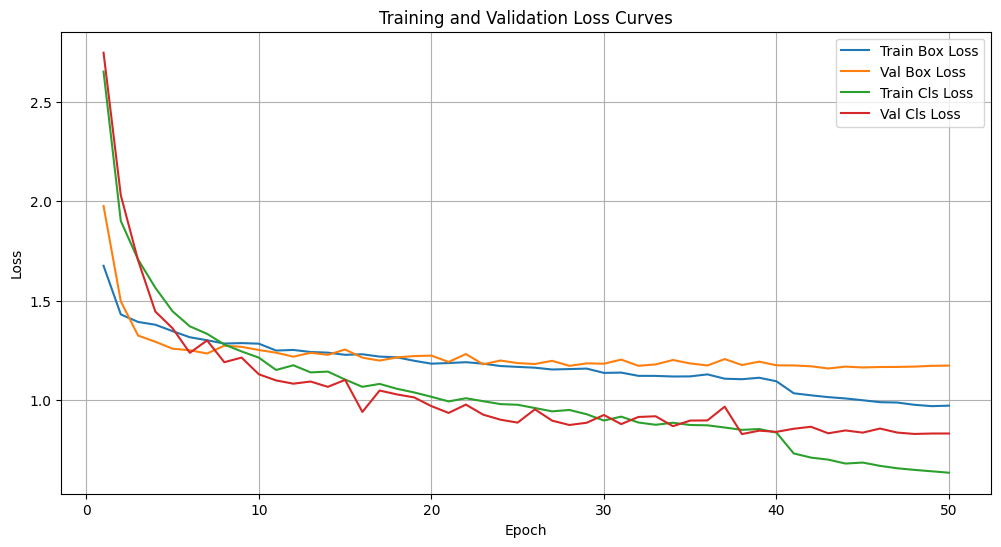

In [43]:
plt.figure(figsize=(12, 6))

if "train/box_loss" in results_df.columns:
    plt.plot(results_df["epoch"], results_df["train/box_loss"], label="Train Box Loss")
if "val/box_loss" in results_df.columns:
    plt.plot(results_df["epoch"], results_df["val/box_loss"], label="Val Box Loss")

if "train/cls_loss" in results_df.columns:
    plt.plot(results_df["epoch"], results_df["train/cls_loss"], label="Train Cls Loss")
if "val/cls_loss" in results_df.columns:
    plt.plot(results_df["epoch"], results_df["val/cls_loss"], label="Val Cls Loss")

plt.title("Training and Validation Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

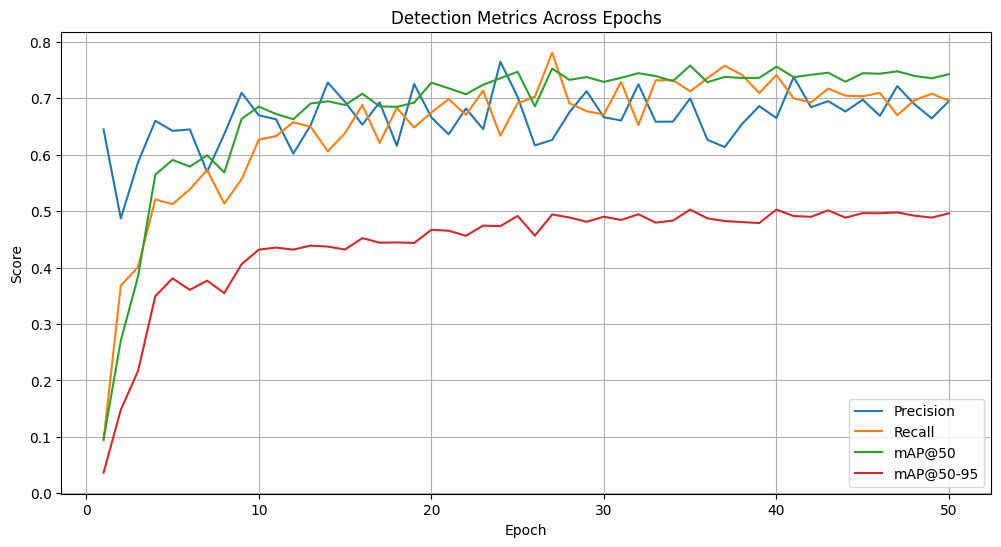

In [44]:
plt.figure(figsize=(12, 6))

if "metrics/precision(B)" in results_df.columns:
    plt.plot(results_df["epoch"], results_df["metrics/precision(B)"], label="Precision")
if "metrics/recall(B)" in results_df.columns:
    plt.plot(results_df["epoch"], results_df["metrics/recall(B)"], label="Recall")
if "metrics/mAP50(B)" in results_df.columns:
    plt.plot(results_df["epoch"], results_df["metrics/mAP50(B)"], label="mAP@50")
if "metrics/mAP50-95(B)" in results_df.columns:
    plt.plot(results_df["epoch"], results_df["metrics/mAP50-95(B)"], label="mAP@50-95")

plt.title("Detection Metrics Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
summary = {
    "best_model_path": best_model_path,
    "results_csv_path": results_csv_path,
    "run_name": RUN_NAME
}

summary_path = f"{PROJECT_DIR}/{RUN_NAME}/baseline_summary.txt"

with open(summary_path, "w") as f:
    for key, value in summary.items():
        f.write(f"{key}: {value}\n")

print("Summary saved at:", summary_path)

Summary saved at: /content/drive/MyDrive/dental_xray_yolo_runs/baseline_yolov8n/baseline_summary.txt


In [46]:
RUN_DIR = "/content/drive/MyDrive/dental_xray_yolo_runs/baseline_yolov8n2"

summary = {
    "best_model_path": f"{RUN_DIR}/weights/best.pt",
    "results_csv_path": f"{RUN_DIR}/results.csv",
    "run_dir": RUN_DIR
}

summary_path = f"{RUN_DIR}/baseline_summary.txt"

with open(summary_path, "w") as f:
    for key, value in summary.items():
        f.write(f"{key}: {value}\n")

print("Summary saved at:", summary_path)

Summary saved at: /content/drive/MyDrive/dental_xray_yolo_runs/baseline_yolov8n2/baseline_summary.txt


In [47]:
BASE_YOLO_DIR = "/content/drive/MyDrive/dental_xray_dataset_yolo"
SR_BASE_DIR = "/content/drive/MyDrive/dental_xray_sr"

TRAIN_HR_IN = os.path.join(BASE_YOLO_DIR, "train", "images")
VALID_HR_IN = os.path.join(BASE_YOLO_DIR, "valid", "images")
TEST_HR_IN  = os.path.join(BASE_YOLO_DIR, "test", "images")

TRAIN_LR_OUT = os.path.join(SR_BASE_DIR, "train", "lr")
TRAIN_HR_OUT = os.path.join(SR_BASE_DIR, "train", "hr")

VALID_LR_OUT = os.path.join(SR_BASE_DIR, "valid", "lr")
VALID_HR_OUT = os.path.join(SR_BASE_DIR, "valid", "hr")

TEST_LR_OUT = os.path.join(SR_BASE_DIR, "test", "lr")
TEST_HR_OUT = os.path.join(SR_BASE_DIR, "test", "hr")

for path in [
    TRAIN_LR_OUT, TRAIN_HR_OUT,
    VALID_LR_OUT, VALID_HR_OUT,
    TEST_LR_OUT, TEST_HR_OUT
]:
    os.makedirs(path, exist_ok=True)

print("SR folders created successfully.")

SR folders created successfully.


In [48]:
def make_low_resolution_image(img, scale_factor=2, apply_blur=True, add_noise=True):
    h, w = img.shape[:2]

    # Downscale
    small = cv2.resize(img, (w // scale_factor, h // scale_factor), interpolation=cv2.INTER_AREA)

    # Mild blur
    if apply_blur:
        small = cv2.GaussianBlur(small, (3, 3), 0)

    # Mild noise
    if add_noise:
        noise = np.random.normal(0, 5, small.shape).astype(np.float32)
        small = np.clip(small.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    # Upscale back to original size
    lr = cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC)

    return lr

In [49]:
def create_sr_pairs(input_hr_dir, output_lr_dir, output_hr_dir, scale_factor=2):
    image_files = sorted([
        f for f in os.listdir(input_hr_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    for fname in tqdm(image_files, desc=f"Processing {os.path.basename(os.path.dirname(input_hr_dir))}"):
        img_path = os.path.join(input_hr_dir, fname)
        hr = cv2.imread(img_path)

        if hr is None:
            print(f"Skipping unreadable image: {img_path}")
            continue

        lr = make_low_resolution_image(hr, scale_factor=scale_factor)

        cv2.imwrite(os.path.join(output_hr_dir, fname), hr)
        cv2.imwrite(os.path.join(output_lr_dir, fname), lr)

In [60]:
def make_low_resolution_image(img, scale_factor=4, apply_blur=True, add_noise=True, jpeg_quality=30):
    h, w = img.shape[:2]

    small = cv2.resize(img, (w // scale_factor, h // scale_factor), interpolation=cv2.INTER_AREA)

    if apply_blur:
        small = cv2.GaussianBlur(small, (5, 5), 0)

    if add_noise:
        noise = np.random.normal(0, 10, small.shape).astype(np.float32)
        small = np.clip(small.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), jpeg_quality]
    _, encimg = cv2.imencode(".jpg", small, encode_param)
    small = cv2.imdecode(encimg, 1)

    lr = cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC)
    return lr

In [61]:
create_sr_pairs(TRAIN_HR_IN, TRAIN_LR_OUT, TRAIN_HR_OUT, scale_factor=4)
create_sr_pairs(VALID_HR_IN, VALID_LR_OUT, VALID_HR_OUT, scale_factor=4)
create_sr_pairs(TEST_HR_IN, TEST_LR_OUT, TEST_HR_OUT, scale_factor=4)

print("LR-HR pair generation completed.")

Processing test: 100%|██████████| 73/73 [00:02<00:00, 31.82it/s]

LR-HR pair generation completed.


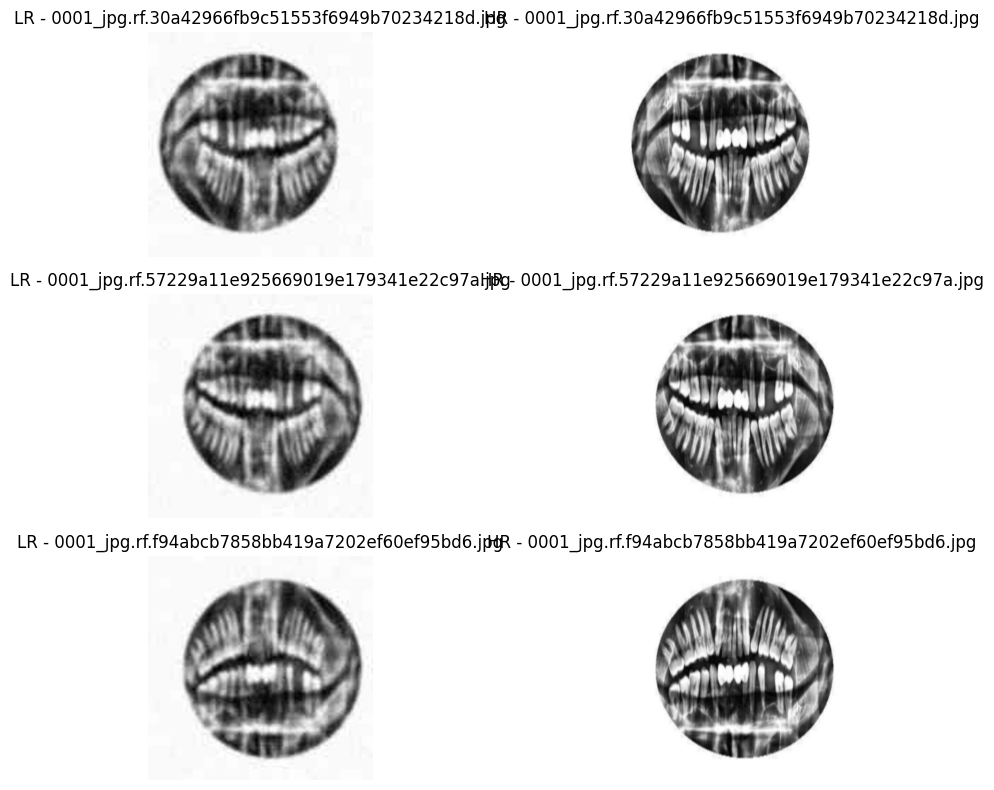

In [62]:
sample_files = sorted(os.listdir(TRAIN_HR_OUT))[:3]

plt.figure(figsize=(12, 8))

for i, fname in enumerate(sample_files):
    hr = cv2.imread(os.path.join(TRAIN_HR_OUT, fname))
    lr = cv2.imread(os.path.join(TRAIN_LR_OUT, fname))

    hr = cv2.cvtColor(hr, cv2.COLOR_BGR2RGB)
    lr = cv2.cvtColor(lr, cv2.COLOR_BGR2RGB)

    plt.subplot(len(sample_files), 2, 2*i + 1)
    plt.imshow(lr)
    plt.title(f"LR - {fname}")
    plt.axis("off")

    plt.subplot(len(sample_files), 2, 2*i + 2)
    plt.imshow(hr)
    plt.title(f"HR - {fname}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [63]:
def count_images(folder):
    return len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

print("Train LR:", count_images(TRAIN_LR_OUT))
print("Train HR:", count_images(TRAIN_HR_OUT))

print("Valid LR:", count_images(VALID_LR_OUT))
print("Valid HR:", count_images(VALID_HR_OUT))

print("Test LR:", count_images(TEST_LR_OUT))
print("Test HR:", count_images(TEST_HR_OUT))

Train LR: 1075
Train HR: 1075
Valid LR: 121
Valid HR: 121
Test LR: 73
Test HR: 73


In [64]:
!pip install -q torch torchvision scikit-image

In [65]:
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [66]:
SR_BASE_DIR = "/content/drive/MyDrive/dental_xray_sr"
SR_RUN_DIR = "/content/drive/MyDrive/dental_xray_sr_runs/srcnn_baseline"

TRAIN_LR_DIR = os.path.join(SR_BASE_DIR, "train", "lr")
TRAIN_HR_DIR = os.path.join(SR_BASE_DIR, "train", "hr")

VALID_LR_DIR = os.path.join(SR_BASE_DIR, "valid", "lr")
VALID_HR_DIR = os.path.join(SR_BASE_DIR, "valid", "hr")

TEST_LR_DIR = os.path.join(SR_BASE_DIR, "test", "lr")
TEST_HR_DIR = os.path.join(SR_BASE_DIR, "test", "hr")

os.makedirs(SR_RUN_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("Run directory:", SR_RUN_DIR)

Using device: cuda
Run directory: /content/drive/MyDrive/dental_xray_sr_runs/srcnn_baseline


In [67]:
class DentalSRDataset(Dataset):
    def __init__(self, lr_dir, hr_dir):
        self.lr_dir = lr_dir
        self.hr_dir = hr_dir
        self.image_files = sorted([
            f for f in os.listdir(lr_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        fname = self.image_files[idx]

        lr_path = os.path.join(self.lr_dir, fname)
        hr_path = os.path.join(self.hr_dir, fname)

        lr_img = Image.open(lr_path).convert("RGB")
        hr_img = Image.open(hr_path).convert("RGB")

        lr_tensor = self.to_tensor(lr_img)
        hr_tensor = self.to_tensor(hr_img)

        return lr_tensor, hr_tensor, fname

In [68]:
train_dataset = DentalSRDataset(TRAIN_LR_DIR, TRAIN_HR_DIR)
valid_dataset = DentalSRDataset(VALID_LR_DIR, VALID_HR_DIR)
test_dataset  = DentalSRDataset(TEST_LR_DIR, TEST_HR_DIR)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=2, pin_memory=True)

print("Train samples:", len(train_dataset))
print("Valid samples:", len(valid_dataset))
print("Test samples:", len(test_dataset))

Train samples: 1075
Valid samples: 121
Test samples: 73


In [69]:
class SRCNN(nn.Module):
    def __init__(self):
        super(SRCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 32, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )

    def forward(self, x):
        return self.features(x)

model = SRCNN().to(device)
print(model)

SRCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(9, 9), stride=(1, 1), padding=(4, 4))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (3): ReLU(inplace=True)
    (4): Conv2d(32, 3, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  )
)


In [70]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [71]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for lr_imgs, hr_imgs, _ in tqdm(loader, desc="Training", leave=False):
        lr_imgs = lr_imgs.to(device)
        hr_imgs = hr_imgs.to(device)

        optimizer.zero_grad()
        sr_imgs = model(lr_imgs)
        loss = criterion(sr_imgs, hr_imgs)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(loader)


def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0

    with torch.no_grad():
        for lr_imgs, hr_imgs, _ in tqdm(loader, desc="Validating", leave=False):
            lr_imgs = lr_imgs.to(device)
            hr_imgs = hr_imgs.to(device)

            sr_imgs = model(lr_imgs)
            loss = criterion(sr_imgs, hr_imgs)

            running_loss += loss.item()

    return running_loss / len(loader)

In [72]:
num_epochs = 20

train_losses = []
valid_losses = []

best_val_loss = float("inf")
best_model_path = os.path.join(SR_RUN_DIR, "best_srcnn.pth")

for epoch in range(num_epochs):
    print(f"\nEpoch [{epoch+1}/{num_epochs}]")

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    valid_loss = validate_one_epoch(model, valid_loader, criterion, device)

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    print(f"Train Loss: {train_loss:.6f}")
    print(f"Valid Loss: {valid_loss:.6f}")

    if valid_loss < best_val_loss:
        best_val_loss = valid_loss
        torch.save(model.state_dict(), best_model_path)
        print("Best model saved.")

print("\nTraining completed.")
print("Best model path:", best_model_path)


Epoch [1/20]


Train Loss: 0.033418
Valid Loss: 0.003395
Best model saved.

Epoch [2/20]


Train Loss: 0.002724
Valid Loss: 0.002376
Best model saved.

Epoch [3/20]


Train Loss: 0.002341
Valid Loss: 0.002235
Best model saved.

Epoch [4/20]


Train Loss: 0.002244
Valid Loss: 0.002204
Best model saved.

Epoch [5/20]


Train Loss: 0.002191
Valid Loss: 0.002165
Best model saved.

Epoch [6/20]


... (11 outputs left out)

Train Loss: 0.001975
Valid Loss: 0.001944

Epoch [18/20]


Train Loss: 0.001966
Valid Loss: 0.001924
Best model saved.

Epoch [19/20]


Train Loss: 0.001955
Valid Loss: 0.001917
Best model saved.

Epoch [20/20]


Train Loss: 0.001951
Valid Loss: 0.001896
Best model saved.

Training completed.
Best model path: /content/drive/MyDrive/dental_xray_sr_runs/srcnn_baseline/best_srcnn.pth


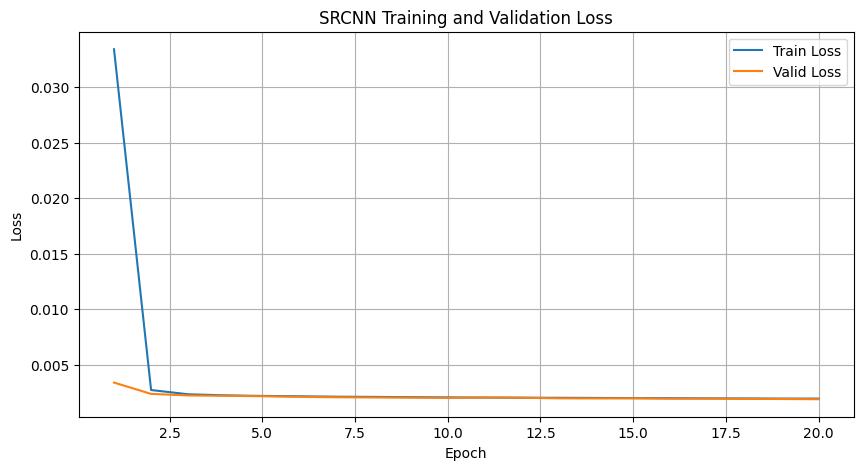

In [73]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_losses, label="Train Loss")
plt.plot(range(1, num_epochs + 1), valid_losses, label="Valid Loss")
plt.title("SRCNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [74]:
best_model = SRCNN().to(device)
best_model.load_state_dict(torch.load(best_model_path, map_location=device))
best_model.eval()

print("Best SRCNN model loaded successfully.")

Best SRCNN model loaded successfully.


In [75]:
psnr_scores = []
ssim_scores = []

with torch.no_grad():
    for lr_imgs, hr_imgs, _ in tqdm(test_loader, desc="Testing SRCNN"):
        lr_imgs = lr_imgs.to(device)
        hr_imgs = hr_imgs.to(device)

        sr_imgs = best_model(lr_imgs)

        sr_np = sr_imgs.squeeze(0).cpu().numpy().transpose(1, 2, 0)
        hr_np = hr_imgs.squeeze(0).cpu().numpy().transpose(1, 2, 0)

        sr_np = np.clip(sr_np, 0, 1)
        hr_np = np.clip(hr_np, 0, 1)

        psnr_val = psnr_metric(hr_np, sr_np, data_range=1.0)
        ssim_val = ssim_metric(hr_np, sr_np, channel_axis=2, data_range=1.0)

        psnr_scores.append(psnr_val)
        ssim_scores.append(ssim_val)

print(f"Average PSNR: {np.mean(psnr_scores):.4f}")
print(f"Average SSIM: {np.mean(ssim_scores):.4f}")

Testing SRCNN: 100%|██████████| 73/73 [00:08<00:00,  8.24it/s]

Average PSNR: 27.3364
Average SSIM: 0.8582


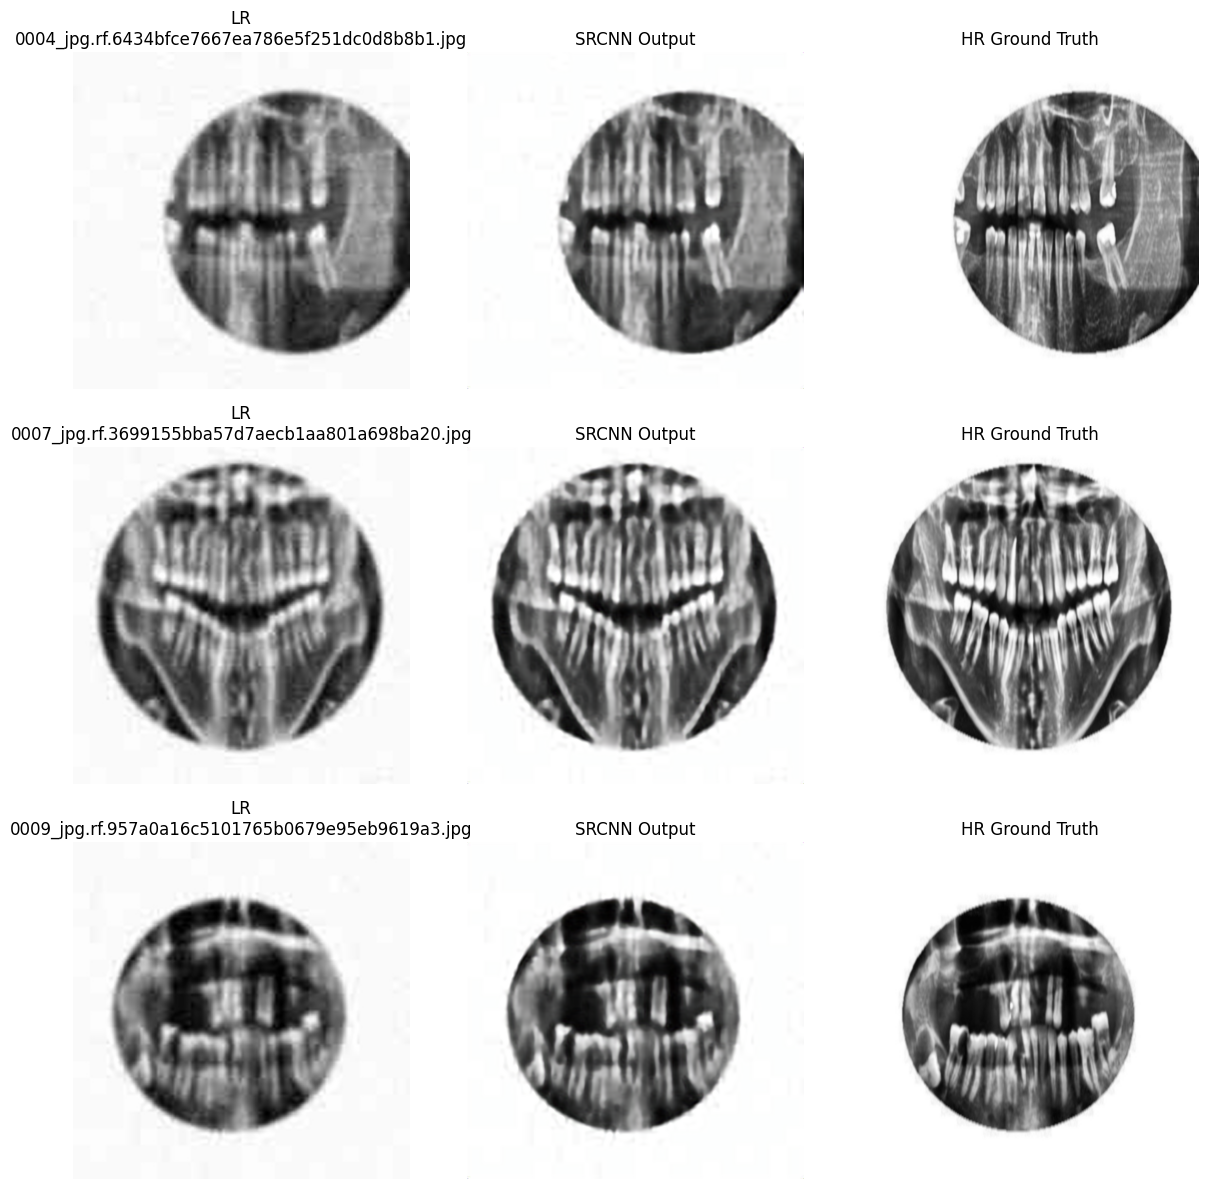

In [76]:
sample_count = 3
shown = 0

plt.figure(figsize=(12, 12))

with torch.no_grad():
    for lr_imgs, hr_imgs, fnames in test_loader:
        lr_imgs = lr_imgs.to(device)
        sr_imgs = best_model(lr_imgs)

        lr_np = lr_imgs.squeeze(0).cpu().numpy().transpose(1, 2, 0)
        sr_np = sr_imgs.squeeze(0).cpu().numpy().transpose(1, 2, 0)
        hr_np = hr_imgs.squeeze(0).cpu().numpy().transpose(1, 2, 0)

        lr_np = np.clip(lr_np, 0, 1)
        sr_np = np.clip(sr_np, 0, 1)
        hr_np = np.clip(hr_np, 0, 1)

        plt.subplot(sample_count, 3, shown * 3 + 1)
        plt.imshow(lr_np)
        plt.title(f"LR\n{fnames[0]}")
        plt.axis("off")

        plt.subplot(sample_count, 3, shown * 3 + 2)
        plt.imshow(sr_np)
        plt.title("SRCNN Output")
        plt.axis("off")

        plt.subplot(sample_count, 3, shown * 3 + 3)
        plt.imshow(hr_np)
        plt.title("HR Ground Truth")
        plt.axis("off")

        shown += 1
        if shown >= sample_count:
            break

plt.tight_layout()
plt.show()

In [77]:
summary_path = os.path.join(SR_RUN_DIR, "srcnn_summary.txt")

with open(summary_path, "w") as f:
    f.write(f"Best Model Path: {best_model_path}\n")
    f.write(f"Average PSNR: {np.mean(psnr_scores):.4f}\n")
    f.write(f"Average SSIM: {np.mean(ssim_scores):.4f}\n")

print("SRCNN summary saved at:", summary_path)

SRCNN summary saved at: /content/drive/MyDrive/dental_xray_sr_runs/srcnn_baseline/srcnn_summary.txt


In [78]:
import shutil

SRCNN_MODEL_PATH = "/content/drive/MyDrive/dental_xray_sr_runs/srcnn_baseline/best_srcnn.pth"

SR_BASE_DIR = "/content/drive/MyDrive/dental_xray_sr"
YOLO_BASE_DIR = "/content/drive/MyDrive/dental_xray_dataset_yolo"

ENHANCED_YOLO_DIR = "/content/drive/MyDrive/dental_xray_dataset_enhanced_yolo"

# LR image sources
TRAIN_LR_DIR = os.path.join(SR_BASE_DIR, "train", "lr")
VALID_LR_DIR = os.path.join(SR_BASE_DIR, "valid", "lr")
TEST_LR_DIR  = os.path.join(SR_BASE_DIR, "test", "lr")

# Original YOLO label sources
TRAIN_LABEL_DIR = os.path.join(YOLO_BASE_DIR, "train", "labels")
VALID_LABEL_DIR = os.path.join(YOLO_BASE_DIR, "valid", "labels")
TEST_LABEL_DIR  = os.path.join(YOLO_BASE_DIR, "test", "labels")

# Enhanced dataset output
TRAIN_ENH_IMG_DIR = os.path.join(ENHANCED_YOLO_DIR, "train", "images")
TRAIN_ENH_LBL_DIR = os.path.join(ENHANCED_YOLO_DIR, "train", "labels")

VALID_ENH_IMG_DIR = os.path.join(ENHANCED_YOLO_DIR, "valid", "images")
VALID_ENH_LBL_DIR = os.path.join(ENHANCED_YOLO_DIR, "valid", "labels")

TEST_ENH_IMG_DIR = os.path.join(ENHANCED_YOLO_DIR, "test", "images")
TEST_ENH_LBL_DIR = os.path.join(ENHANCED_YOLO_DIR, "test", "labels")

for path in [
    TRAIN_ENH_IMG_DIR, TRAIN_ENH_LBL_DIR,
    VALID_ENH_IMG_DIR, VALID_ENH_LBL_DIR,
    TEST_ENH_IMG_DIR, TEST_ENH_LBL_DIR
]:
    os.makedirs(path, exist_ok=True)

print("Enhanced YOLO folders created.")

Enhanced YOLO folders created.


In [79]:
import torch.nn as nn

class SRCNN(nn.Module):
    def __init__(self):
        super(SRCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )

    def forward(self, x):
        return self.features(x)

In [80]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SRCNN().to(device)
model.load_state_dict(torch.load(SRCNN_MODEL_PATH, map_location=device))
model.eval()

to_tensor = transforms.ToTensor()
to_pil = transforms.ToPILImage()

print("SRCNN model loaded successfully.")
print("Using device:", device)

SRCNN model loaded successfully.
Using device: cuda


In [81]:
def enhance_and_prepare_split(lr_img_dir, src_label_dir, out_img_dir, out_label_dir):
    image_files = sorted([
        f for f in os.listdir(lr_img_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    with torch.no_grad():
        for fname in tqdm(image_files, desc=f"Enhancing {os.path.basename(os.path.dirname(lr_img_dir))}"):
            img_path = os.path.join(lr_img_dir, fname)

            # Load LR image
            img = Image.open(img_path).convert("RGB")
            img_tensor = to_tensor(img).unsqueeze(0).to(device)

            # SRCNN inference
            sr_tensor = model(img_tensor).squeeze(0).cpu().clamp(0, 1)
            sr_img = to_pil(sr_tensor)

            # Save enhanced image
            out_img_path = os.path.join(out_img_dir, fname)
            sr_img.save(out_img_path)

            # Copy corresponding YOLO label file
            txt_name = os.path.splitext(fname)[0] + ".txt"
            src_txt_path = os.path.join(src_label_dir, txt_name)
            dst_txt_path = os.path.join(out_label_dir, txt_name)

            if os.path.exists(src_txt_path):
                shutil.copy(src_txt_path, dst_txt_path)
            else:
                print(f"Warning: missing label for {fname}")

In [82]:
enhance_and_prepare_split(TRAIN_LR_DIR, TRAIN_LABEL_DIR, TRAIN_ENH_IMG_DIR, TRAIN_ENH_LBL_DIR)
enhance_and_prepare_split(VALID_LR_DIR, VALID_LABEL_DIR, VALID_ENH_IMG_DIR, VALID_ENH_LBL_DIR)
enhance_and_prepare_split(TEST_LR_DIR, TEST_LABEL_DIR, TEST_ENH_IMG_DIR, TEST_ENH_LBL_DIR)

print("Enhanced YOLO dataset generated successfully.")

Enhancing test: 100%|██████████| 73/73 [00:04<00:00, 16.24it/s]

Enhanced YOLO dataset generated successfully.


In [83]:
class_names = ["Cavity", "Fillings", "Impacted_Tooth", "Implant"]

yaml_content = f"""train: {TRAIN_ENH_IMG_DIR}
val: {VALID_ENH_IMG_DIR}
test: {TEST_ENH_IMG_DIR}

nc: {len(class_names)}
names: {class_names}
"""

yaml_path = os.path.join(ENHANCED_YOLO_DIR, "data.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("Enhanced data.yaml created at:", yaml_path)
print("\nYAML content:\n")
print(yaml_content)

Enhanced data.yaml created at: /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/data.yaml

YAML content:

train: /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/train/images
val: /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/valid/images
test: /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/test/images

nc: 4
names: ['Cavity', 'Fillings', 'Impacted_Tooth', 'Implant']



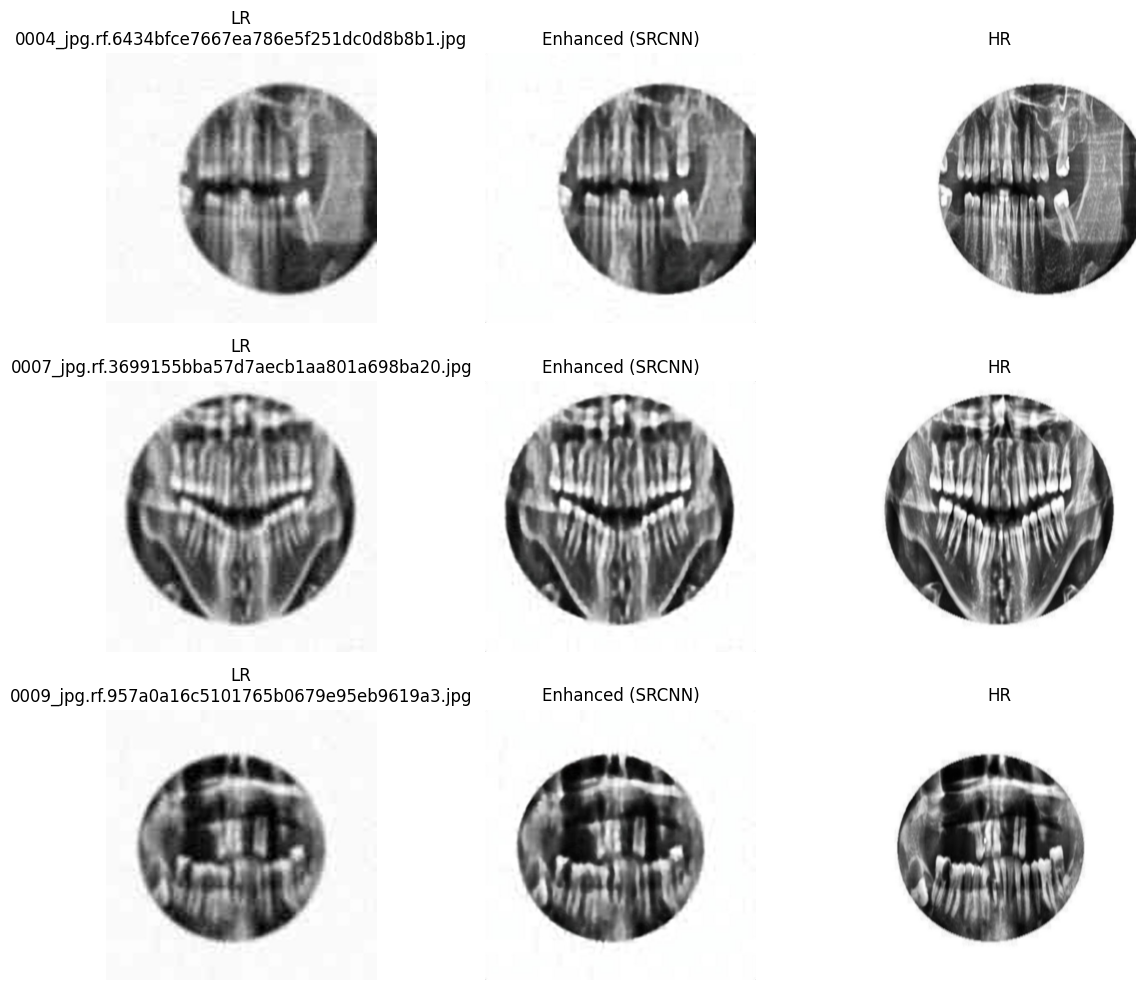

In [84]:
sample_files = sorted(os.listdir(TEST_LR_DIR))[:3]

plt.figure(figsize=(12, 10))

for i, fname in enumerate(sample_files):
    lr = Image.open(os.path.join(TEST_LR_DIR, fname)).convert("RGB")
    enh = Image.open(os.path.join(TEST_ENH_IMG_DIR, fname)).convert("RGB")
    hr = Image.open(os.path.join(os.path.join(SR_BASE_DIR, "test", "hr"), fname)).convert("RGB")

    plt.subplot(len(sample_files), 3, 3*i + 1)
    plt.imshow(lr)
    plt.title(f"LR\n{fname}")
    plt.axis("off")

    plt.subplot(len(sample_files), 3, 3*i + 2)
    plt.imshow(enh)
    plt.title("Enhanced (SRCNN)")
    plt.axis("off")

    plt.subplot(len(sample_files), 3, 3*i + 3)
    plt.imshow(hr)
    plt.title("HR")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [85]:
def count_files(folder, exts=(".jpg", ".jpeg", ".png", ".txt")):
    return len([f for f in os.listdir(folder) if f.lower().endswith(exts)])

print("Train enhanced images:", count_files(TRAIN_ENH_IMG_DIR, exts=(".jpg", ".jpeg", ".png")))
print("Train labels:", count_files(TRAIN_ENH_LBL_DIR, exts=(".txt",)))

print("Valid enhanced images:", count_files(VALID_ENH_IMG_DIR, exts=(".jpg", ".jpeg", ".png")))
print("Valid labels:", count_files(VALID_ENH_LBL_DIR, exts=(".txt",)))

print("Test enhanced images:", count_files(TEST_ENH_IMG_DIR, exts=(".jpg", ".jpeg", ".png")))
print("Test labels:", count_files(TEST_ENH_LBL_DIR, exts=(".txt",)))

Train enhanced images: 1075
Train labels: 1075
Valid enhanced images: 121
Valid labels: 121
Test enhanced images: 73
Test labels: 73


In [86]:
!pip install -q ultralytics


In [87]:
from ultralytics import YOLO

ENHANCED_YAML = "/content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/data.yaml"
PROJECT_DIR_ENH = "/content/drive/MyDrive/dental_xray_yolo_runs_enhanced"
RUN_NAME_ENH = "srcnn_yolov8n"

os.makedirs(PROJECT_DIR_ENH, exist_ok=True)

print("Enhanced YAML:", ENHANCED_YAML)
print("Enhanced project dir:", PROJECT_DIR_ENH)

Enhanced YAML: /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/data.yaml
Enhanced project dir: /content/drive/MyDrive/dental_xray_yolo_runs_enhanced


In [88]:
if os.path.exists(ENHANCED_YAML):
    print("Enhanced data.yaml found.\n")
    with open(ENHANCED_YAML, "r") as f:
        print(f.read())
else:
    print("ERROR: Enhanced data.yaml not found.")

Enhanced data.yaml found.

train: /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/train/images
val: /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/valid/images
test: /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/test/images

nc: 4
names: ['Cavity', 'Fillings', 'Impacted_Tooth', 'Implant']



In [89]:
enh_model = YOLO("yolov8n.pt")
print("YOLO model for enhanced training loaded.")

YOLO model for enhanced training loaded.


In [90]:
enh_results = enh_model.train(
    data=ENHANCED_YAML,
    epochs=50,
    imgsz=640,
    batch=8,
    project=PROJECT_DIR_ENH,
    name=RUN_NAME_ENH,
    pretrained=True,
    optimizer="Adam",
    lr0=0.001,
    patience=15,
    workers=2,
    plots=True
)

Ultralytics 8.4.32 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=srcnn_yolov8n, nbs=64, nms=False, opset=None, optimize=False, optimizer=Adam,

In [91]:
best_enh_model_path = None
best_enh_run_dir = None

for run_name in sorted(os.listdir(PROJECT_DIR_ENH), reverse=True):
    candidate = os.path.join(PROJECT_DIR_ENH, run_name, "weights", "best.pt")
    if os.path.exists(candidate):
        best_enh_model_path = candidate
        best_enh_run_dir = os.path.join(PROJECT_DIR_ENH, run_name)
        break

print("Best enhanced model path:", best_enh_model_path)
print("Best enhanced run dir:", best_enh_run_dir)

Best enhanced model path: /content/drive/MyDrive/dental_xray_yolo_runs_enhanced/srcnn_yolov8n/weights/best.pt
Best enhanced run dir: /content/drive/MyDrive/dental_xray_yolo_runs_enhanced/srcnn_yolov8n


In [92]:
best_enh_model = YOLO(best_enh_model_path)

enh_val_metrics = best_enh_model.val(data=ENHANCED_YAML, split="val")
enh_test_metrics = best_enh_model.val(data=ENHANCED_YAML, split="test")

print("Enhanced model validation and testing finished.")

Ultralytics 8.4.32 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 5.6±5.0 ms, read: 2.0±1.4 MB/s, size: 25.1 KB)
val: Scanning /content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/valid/labels.cache... 121 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 121/121 28.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.7it/s 4.8s
                   all        121        780      0.596      0.533      0.587       0.35
                Cavity         23         43      0.404      0.326      0.294      0.134
              Fillings         97        540      0.654      0.577       0.65      0.389
        Impacted_Tooth         25         38      0.629      0.605      0.691      0.442
               Implant         59        159      0.697      0.622      0.712      0.434
Speed: 5.6ms pre

In [93]:
TEST_ENH_IMG_DIR = "/content/drive/MyDrive/dental_xray_dataset_enhanced_yolo/test/images"

sample_test_images = sorted([
    os.path.join(TEST_ENH_IMG_DIR, f)
    for f in os.listdir(TEST_ENH_IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])[:5]

pred_results = best_enh_model.predict(
    source=sample_test_images,
    conf=0.25,
    save=True,
    project=PROJECT_DIR_ENH,
    name="enhanced_predictions"
)

print("Enhanced predictions saved.")


0: 640x640 2 Fillingss, 5.5ms
1: 640x640 2 Implants, 5.5ms
2: 640x640 1 Cavity, 6 Fillingss, 1 Implant, 5.5ms
3: 640x640 3 Cavitys, 4 Fillingss, 1 Impacted_Tooth, 5.5ms
4: 640x640 2 Fillingss, 2 Implants, 5.5ms
Speed: 3.7ms preprocess, 5.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/dental_xray_yolo_runs_enhanced/enhanced_predictions
Enhanced predictions saved.


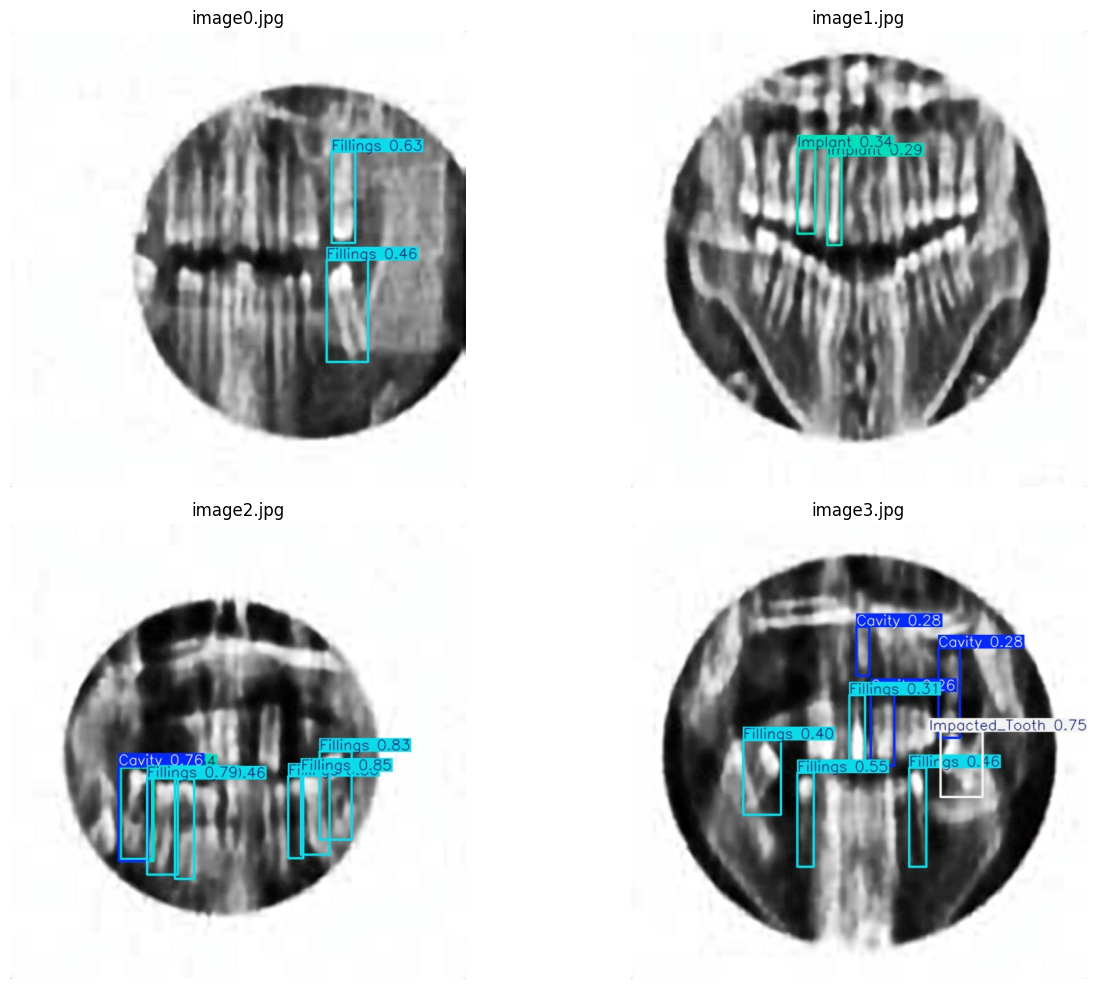

In [94]:
PRED_DIR_ENH = f"{PROJECT_DIR_ENH}/enhanced_predictions"

predicted_files = sorted([
    os.path.join(PRED_DIR_ENH, f)
    for f in os.listdir(PRED_DIR_ENH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

num_images = min(4, len(predicted_files))
cols = 2
rows = math.ceil(num_images / cols)

plt.figure(figsize=(14, 10))

for i in range(num_images):
    img = cv2.imread(predicted_files[i])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(predicted_files[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [95]:
enh_results_csv_path = os.path.join(best_enh_run_dir, "results.csv")

enh_results_df = pd.read_csv(enh_results_csv_path)
print(enh_results_df.head())
print("\nColumns:")
print(enh_results_df.columns.tolist())

   epoch      time  train/box_loss  train/cls_loss  train/dfl_loss  \
0      1   28.4423         1.98458         2.81984         1.58293   
1      2   55.6678         1.71264         2.09613         1.41051   
2      3   83.7062         1.66712         1.94038         1.39170   
3      4  111.4520         1.63284         1.84385         1.38219   
4      5  137.5730         1.60821         1.74867         1.35181   

   metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
0               0.63958            0.11530           0.09901   
1               0.43570            0.28860           0.15896   
2               0.52606            0.36302           0.29856   
3               0.61685            0.30681           0.30006   
4               0.54163            0.45544           0.35462   

   metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss    lr/pg0  \
0              0.04634       1.94919       2.77212       1.61283  0.000331   
1              0.07109       1.86373  

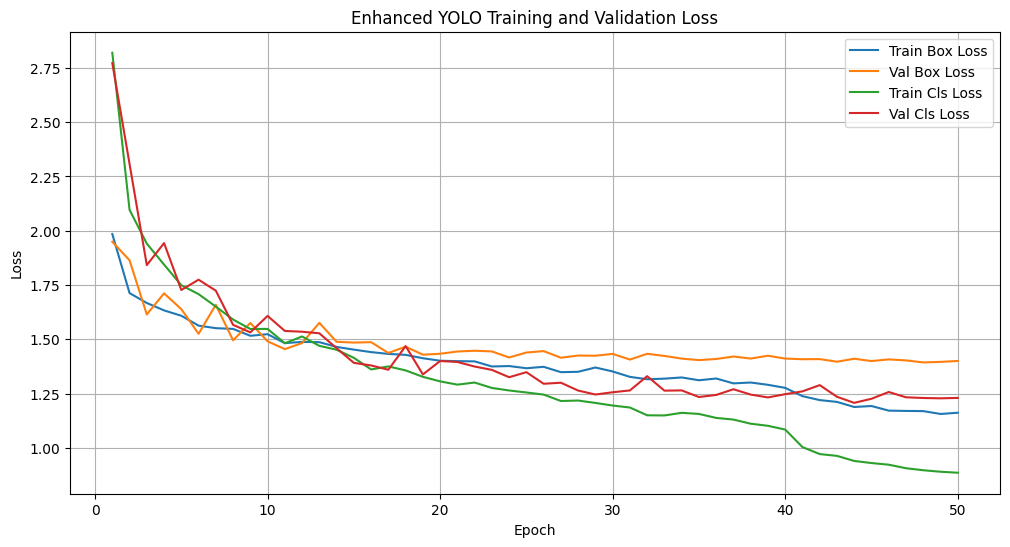

In [96]:
plt.figure(figsize=(12, 6))

if "train/box_loss" in enh_results_df.columns:
    plt.plot(enh_results_df["epoch"], enh_results_df["train/box_loss"], label="Train Box Loss")
if "val/box_loss" in enh_results_df.columns:
    plt.plot(enh_results_df["epoch"], enh_results_df["val/box_loss"], label="Val Box Loss")

if "train/cls_loss" in enh_results_df.columns:
    plt.plot(enh_results_df["epoch"], enh_results_df["train/cls_loss"], label="Train Cls Loss")
if "val/cls_loss" in enh_results_df.columns:
    plt.plot(enh_results_df["epoch"], enh_results_df["val/cls_loss"], label="Val Cls Loss")

plt.title("Enhanced YOLO Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

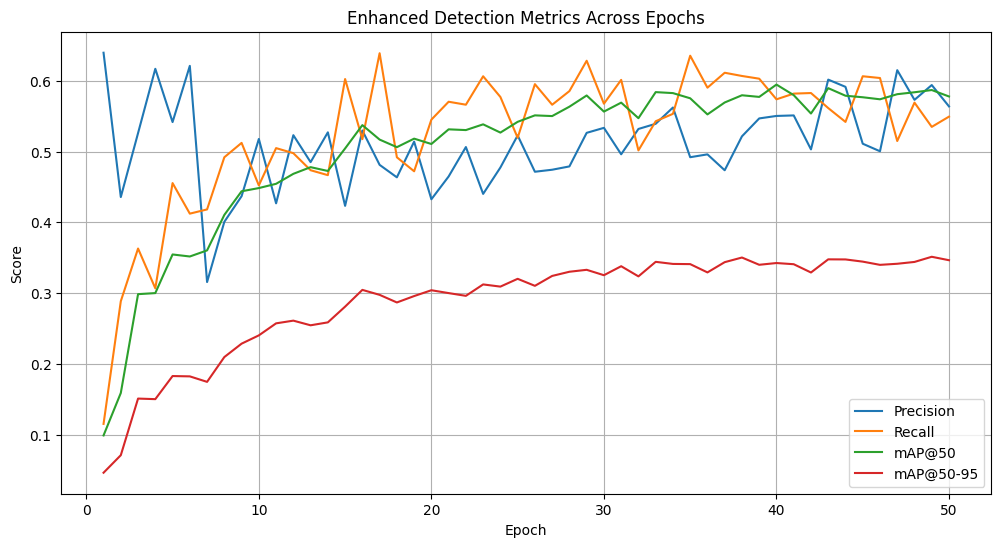

In [97]:
plt.figure(figsize=(12, 6))

if "metrics/precision(B)" in enh_results_df.columns:
    plt.plot(enh_results_df["epoch"], enh_results_df["metrics/precision(B)"], label="Precision")
if "metrics/recall(B)" in enh_results_df.columns:
    plt.plot(enh_results_df["epoch"], enh_results_df["metrics/recall(B)"], label="Recall")
if "metrics/mAP50(B)" in enh_results_df.columns:
    plt.plot(enh_results_df["epoch"], enh_results_df["metrics/mAP50(B)"], label="mAP@50")
if "metrics/mAP50-95(B)" in enh_results_df.columns:
    plt.plot(enh_results_df["epoch"], enh_results_df["metrics/mAP50-95(B)"], label="mAP@50-95")

plt.title("Enhanced Detection Metrics Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

In [98]:
comparison_df = pd.DataFrame({
    "Model": ["Baseline YOLO", "Enhanced YOLO (SRCNN)"],
    "Precision": [0.658, None],
    "Recall": [0.776, None],
    "mAP@50": [0.809, None],
    "mAP@50-95": [0.559, None]
})

print(comparison_df)

                   Model  Precision  Recall  mAP@50  mAP@50-95
0          Baseline YOLO      0.658   0.776   0.809      0.559
1  Enhanced YOLO (SRCNN)        NaN     NaN     NaN        NaN


In [2]:
import pandas as pd
comparison_df = pd.DataFrame({
    "Model": ["Baseline YOLO", "Enhanced YOLO (SRCNN)"],
    "Precision": [0.658, 0.571],
    "Recall": [0.776, 0.501],
    "mAP@50": [0.809, 0.560],
    "mAP@50-95": [0.559, 0.305]
})

print(comparison_df)

                   Model  Precision  Recall  mAP@50  mAP@50-95
0          Baseline YOLO      0.658   0.776   0.809      0.559
1  Enhanced YOLO (SRCNN)      0.571   0.501   0.560      0.305


In [3]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": ["Baseline YOLO", "Enhanced YOLO (SRCNN)"],
    "Precision": [0.658, 0.571],
    "Recall": [0.776, 0.501],
    "mAP@50": [0.809, 0.560],
    "mAP@50-95": [0.559, 0.305]
})

comparison_df.to_csv("/content/drive/MyDrive/final_model_comparison.csv", index=False)
print(comparison_df)

                   Model  Precision  Recall  mAP@50  mAP@50-95
0          Baseline YOLO      0.658   0.776   0.809      0.559
1  Enhanced YOLO (SRCNN)      0.571   0.501   0.560      0.305


In [4]:
from google.colab import files
import shutil
import os

# ===== PATHS (CHANGE ONLY IF YOUR FOLDERS ARE DIFFERENT) =====
yolo_path = "/content/drive/MyDrive/dental_xray_yolo_runs/baseline_yolov8n2/weights/best.pt"
srcnn_path = "/content/drive/MyDrive/dental_xray_sr_runs/srcnn_baseline/best_srcnn.pth"

# ===== COPY TO /content (required for download) =====
local_yolo = "/content/baseline_yolo_best.pt"
local_srcnn = "/content/best_srcnn.pth"

shutil.copy(yolo_path, local_yolo)
shutil.copy(srcnn_path, local_srcnn)

print("Files copied to /content successfully.")

# ===== DOWNLOAD =====
files.download(local_yolo)
files.download(local_srcnn)

Files copied to /content successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

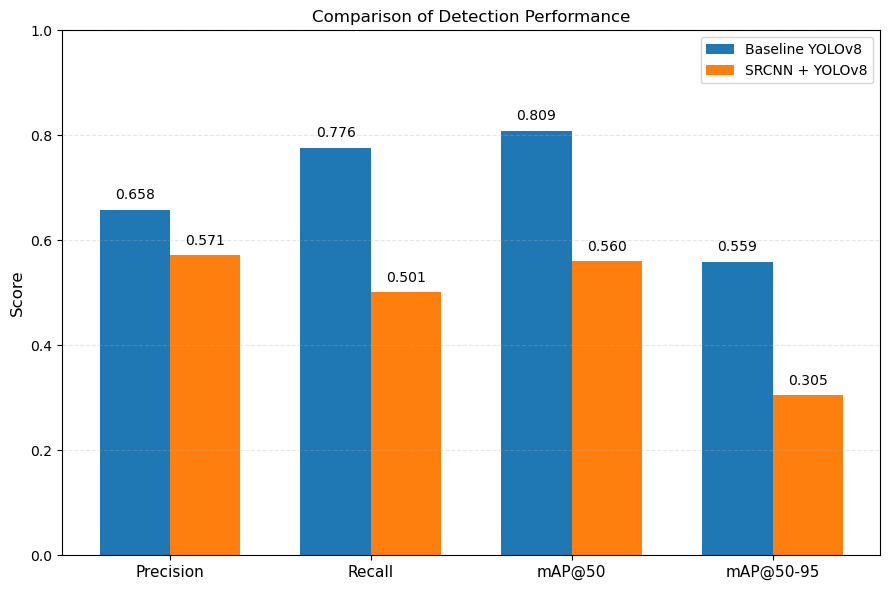

In [1]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "mAP@50", "mAP@50-95"]

baseline = [0.658, 0.776, 0.809, 0.559]
enhanced = [0.571, 0.501, 0.560, 0.305]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9,6))

plt.bar(x-width/2, baseline, width, label="Baseline YOLOv8")
plt.bar(x+width/2, enhanced, width, label="SRCNN + YOLOv8")

plt.xticks(x, metrics, fontsize=11)
plt.ylabel("Score", fontsize=12)
plt.title("Comparison of Detection Performance")
plt.ylim(0,1)

for i,v in enumerate(baseline):
    plt.text(i-width/2,v+0.02,f"{v:.3f}",ha='center')

for i,v in enumerate(enhanced):
    plt.text(i+width/2,v+0.02,f"{v:.3f}",ha='center')

plt.legend()
plt.grid(axis='y',linestyle='--',alpha=0.3)
plt.tight_layout()
plt.show()

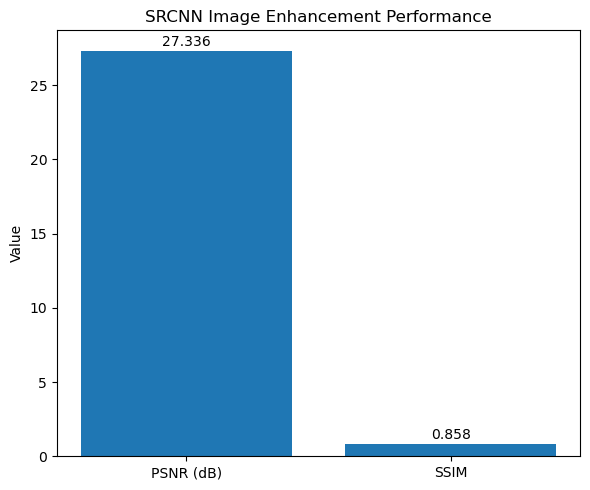

In [2]:
import matplotlib.pyplot as plt

metrics = ["PSNR (dB)", "SSIM"]
values = [27.3364,0.8582]

plt.figure(figsize=(6,5))

bars=plt.bar(metrics,values)

for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.3,
             f"{bar.get_height():.3f}",
             ha='center')

plt.title("SRCNN Image Enhancement Performance")
plt.ylabel("Value")

plt.tight_layout()
plt.show()

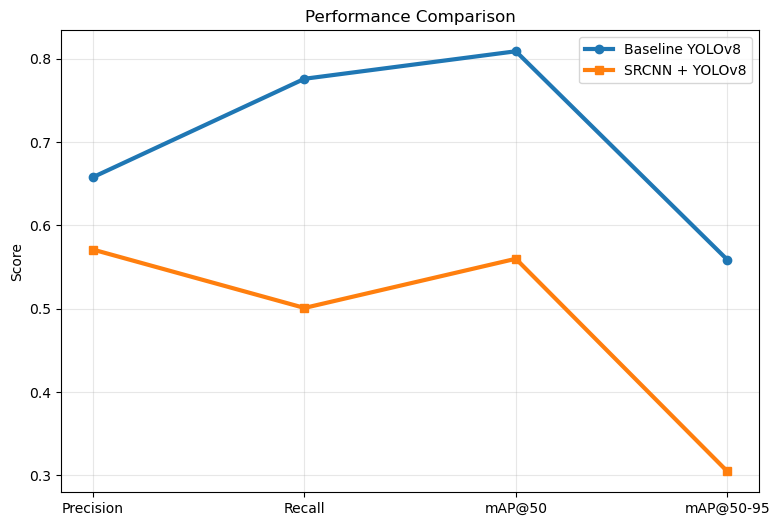

In [3]:
import matplotlib.pyplot as plt

metrics=["Precision","Recall","mAP@50","mAP@50-95"]

baseline=[0.658,0.776,0.809,0.559]
enhanced=[0.571,0.501,0.560,0.305]

plt.figure(figsize=(9,6))

plt.plot(metrics,baseline,marker='o',linewidth=3,label="Baseline YOLOv8")
plt.plot(metrics,enhanced,marker='s',linewidth=3,label="SRCNN + YOLOv8")

plt.ylabel("Score")
plt.title("Performance Comparison")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

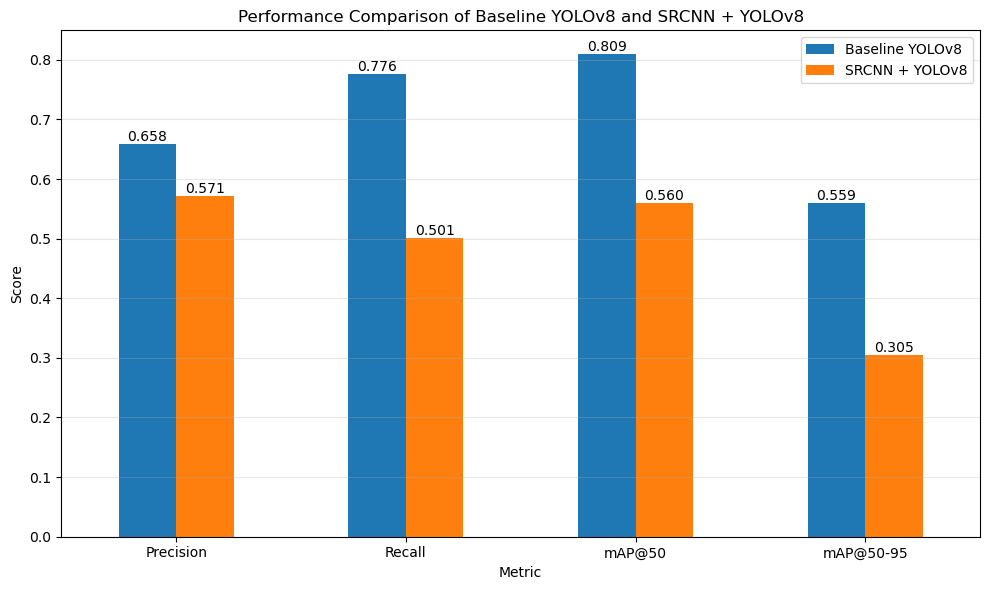

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.DataFrame({
    "Metric":["Precision","Recall","mAP@50","mAP@50-95"],
    "Baseline YOLOv8":[0.658,0.776,0.809,0.559],
    "SRCNN + YOLOv8":[0.571,0.501,0.560,0.305]
})

ax=df.set_index("Metric").plot(kind="bar",figsize=(10,6))

plt.ylabel("Score")
plt.title("Performance Comparison of Baseline YOLOv8 and SRCNN + YOLOv8")

for container in ax.containers:
    ax.bar_label(container,fmt="%.3f")

plt.xticks(rotation=0)
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()